# 03 - Regularización, overfitting y diagnóstico bias/variance

Se usará una muestra estratificada de 12.000 imágenes del conjunto Train para comparar una red grande sin regularización frente a otra con L2, Dropout y Early Stopping. Dev se utiliza para monitorear generalización. Test no participa en esta comparación.

## 1. Preparar entorno y datos

In [ ]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers, callbacks
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
OUTPUT_DIR = Path("resultados")
OUTPUT_DIR.mkdir(exist_ok=True)
print("TensorFlow:", tf.__version__)
print("Semilla:", SEED)

TensorFlow: 2.21.0
Semilla: 42


In [ ]:
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.mnist.load_data()

x_train, x_dev, y_train, y_dev = train_test_split(
    x_train_full, y_train_full,
    test_size=0.20,
    random_state=SEED,
    stratify=y_train_full
)

# Las imágenes se mantienen en escala de grises (28 x 28); solo se escala su intensidad.
x_train = x_train.astype("float32") / 255.0
x_dev   = x_dev.astype("float32") / 255.0
x_test  = x_test.astype("float32") / 255.0

print("Train:", x_train.shape, y_train.shape)
print("Dev:", x_dev.shape, y_dev.shape)
print("Test:", x_test.shape, y_test.shape)
print("Rango de Train:", float(x_train.min()), float(x_train.max()))

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train: (48000, 28, 28) (48000,)
Dev: (12000, 28, 28) (12000,)
Test: (10000, 28, 28) (10000,)
Rango de Train: 0.0 1.0


## 2. Obtener muestra estratificada de 12.000 imágenes

In [ ]:
x_train_reg, _, y_train_reg, _ = train_test_split(
    x_train, y_train,
    train_size=12000,
    random_state=SEED,
    stratify=y_train
)
print("Muestra regularización:", x_train_reg.shape, y_train_reg.shape)

Muestra regularización: (12000, 28, 28) (12000,)


## 3. Entrenar modelo sin regularización

In [ ]:
def crear_modelo_sin_regularizacion():
    modelo = keras.Sequential([
        layers.Input(shape=(28, 28)),
        layers.Flatten(),
        layers.Dense(512, activation="relu"),
        layers.Dense(256, activation="relu"),
        layers.Dense(10, activation="softmax")
    ])
    modelo.compile(
        optimizer=keras.optimizers.Adam(0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return modelo

keras.backend.clear_session(); tf.keras.utils.set_random_seed(SEED)
modelo_sin_reg = crear_modelo_sin_regularizacion()
hist_sin_reg = modelo_sin_reg.fit(
    x_train_reg, y_train_reg,
    validation_data=(x_dev, y_dev),
    epochs=15,
    batch_size=64,
    verbose=0
)
print("Épocas sin regularización:", len(hist_sin_reg.history["loss"]))

Épocas sin regularización: 15


## 4. Entrenar modelo con L2, Dropout y Early Stopping

In [ ]:
def crear_modelo_regularizado():
    modelo = keras.Sequential([
        layers.Input(shape=(28, 28)),
        layers.Flatten(),
        layers.Dense(512, activation="relu", kernel_regularizer=regularizers.l2(1e-4)),
        layers.Dropout(0.30),
        layers.Dense(256, activation="relu", kernel_regularizer=regularizers.l2(1e-4)),
        layers.Dropout(0.30),
        layers.Dense(10, activation="softmax")
    ])
    modelo.compile(
        optimizer=keras.optimizers.Adam(0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return modelo

parada_temprana = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

keras.backend.clear_session(); tf.keras.utils.set_random_seed(SEED)
modelo_reg = crear_modelo_regularizado()
hist_reg = modelo_reg.fit(
    x_train_reg, y_train_reg,
    validation_data=(x_dev, y_dev),
    epochs=20,
    batch_size=64,
    callbacks=[parada_temprana],
    verbose=0
)
print("Épocas ejecutadas con Early Stopping:", len(hist_reg.history["loss"]))
modelo_reg.save(OUTPUT_DIR / "modelo_regularizado.keras")
pd.DataFrame(hist_reg.history).to_csv(OUTPUT_DIR / "historial_regularizado.csv", index=False)

Épocas ejecutadas con Early Stopping: 10


## 5. Comparar las curvas de pérdida

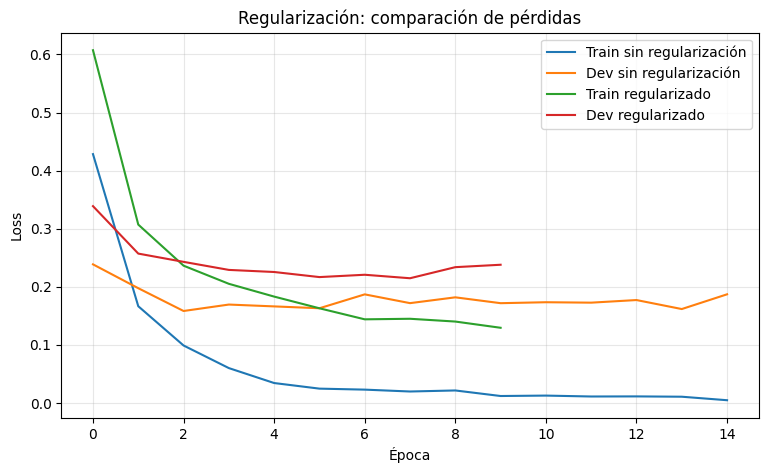

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(hist_sin_reg.history["loss"], label="Train sin regularización")
ax.plot(hist_sin_reg.history["val_loss"], label="Dev sin regularización")
ax.plot(hist_reg.history["loss"], label="Train regularizado")
ax.plot(hist_reg.history["val_loss"], label="Dev regularizado")
ax.set_xlabel("Época"); ax.set_ylabel("Loss"); ax.set_title("Regularización: comparación de pérdidas")
ax.grid(True, alpha=.3); ax.legend(); plt.show()

## 6. Evaluar ambos modelos en Dev y comparar la brecha Train-Dev

In [ ]:
def resumen_modelo(nombre, modelo, historia):
    train_loss, train_acc = modelo.evaluate(x_train_reg, y_train_reg, verbose=0)
    dev_loss, dev_acc = modelo.evaluate(x_dev, y_dev, verbose=0)
    return {
        "modelo": nombre,
        "train_loss": train_loss,
        "dev_loss": dev_loss,
        "train_accuracy": train_acc,
        "dev_accuracy": dev_acc,
        "brecha_accuracy_train_dev": train_acc - dev_acc,
        "epocas": len(historia.history["loss"])
    }

tabla_regularizacion = pd.DataFrame([
    resumen_modelo("Sin regularización", modelo_sin_reg, hist_sin_reg),
    resumen_modelo("L2 + Dropout + Early Stopping", modelo_reg, hist_reg)
])
display(tabla_regularizacion)
tabla_regularizacion.to_csv(OUTPUT_DIR / "comparacion_regularizacion.csv", index=False)

,modelo,train_loss,dev_loss,train_accuracy,dev_accuracy,brecha_accuracy_train_dev,epocas
0,Sin regularización,0.012850,0.186999,0.995750,0.963750,0.032,15
1,L2 + Dropout + Early Stopping,0.109231,0.214654,0.992417,0.965417,0.027,10


## 7. Diagnóstico de bias y variance

In [ ]:
keras.backend.clear_session(); tf.keras.utils.set_random_seed(SEED)
modelo_pequeno = keras.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(16, activation="relu"),
    layers.Dense(10, activation="softmax")
])
modelo_pequeno.compile(
    optimizer=keras.optimizers.Adam(0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
hist_pequeno = modelo_pequeno.fit(
    x_train, y_train,
    validation_data=(x_dev, y_dev),
    epochs=2,
    batch_size=64,
    verbose=0
)

def resumen_historia(nombre, historia):
    train_acc = historia.history["accuracy"][-1]
    dev_acc = historia.history["val_accuracy"][-1]
    return {
        "modelo": nombre,
        "train_accuracy": train_acc,
        "dev_accuracy": dev_acc,
        "brecha_train_dev": train_acc - dev_acc
    }

tabla_diagnostico = pd.DataFrame([
    resumen_historia("Pequeño (16 neuronas)", hist_pequeno),
    resumen_historia("Sin regularización", hist_sin_reg),
    resumen_historia("Regularizado", hist_reg)
])
display(tabla_diagnostico)
tabla_diagnostico.to_csv(OUTPUT_DIR / "diagnostico_bias_variance.csv", index=False)

,modelo,train_accuracy,dev_accuracy,brecha_train_dev
0,Pequeño (16 neuronas),0.918521,0.920583,-0.002062
1,Sin regularización,0.998667,0.963750,0.034917
2,Regularizado,0.984500,0.960667,0.023833


## 8. Análisis requerido

- **Underfitting / bias alto:** Train y Dev permanecen relativamente bajos; la red es demasiado sencilla o no aprende suficiente.
- **Overfitting / variance alta:** Train es mucho mejor que Dev, o Dev deja de mejorar mientras Train continúa mejorando.
- **Equilibrio:** Train y Dev tienen buen rendimiento y una brecha moderada; debe confirmarse con la evaluación de Test.
- Explica si L2, Dropout y Early Stopping redujeron la brecha en tus resultados.
- Indica cuántas épocas ejecutó Early Stopping y por qué.
- No afirmes que la regularización siempre mejora Accuracy; describe lo observado.